# Cross-Species Urease Potency Transferability
## Paired Inhibition Analysis


In [1]:
import sys, subprocess, importlib.util
for package in ['numpy','pandas','scipy','matplotlib']:
    if importlib.util.find_spec(package) is None:
        subprocess.check_call([sys.executable,'-m','pip','install','-q',package])
import io, csv, json, hashlib, gzip, base64, pathlib, zipfile, warnings
import numpy as np, pandas as pd
from scipy.stats import spearmanr, pearsonr
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from IPython.display import display, Image
from matplotlib.ticker import FuncFormatter
OUTPUT = pathlib.Path('/content/JBU_HPU_46_13_Studies') if pathlib.Path('/content').exists() else (pathlib.Path('/mnt/data/JBU_HPU_46_13_Studies') if pathlib.Path('/mnt/data').exists() else pathlib.Path.cwd()/'JBU_HPU_46_13_Studies')
OUTPUT.mkdir(parents=True,exist_ok=True)
plt.rcParams.update({'font.family':'DejaVu Sans','font.size':9,'axes.labelsize':11,'axes.labelweight':'bold','axes.linewidth':1.45,'xtick.labelsize':9,'ytick.labelsize':9,'savefig.dpi':600,'pdf.fonttype':42,'ps.fonttype':42,'figure.dpi':125})
print('Output folder:', OUTPUT)


Output folder: /mnt/data/JBU_HPU_46_13_Studies


In [2]:
# Embedded complete 45-row CSV. Fixed SHA-256 enables exact offline reproduction.
# The original 43 records are separately integrity-checked in the next cell.
EMBEDDED_DATA_GZIP_B64 = 'H4sIADmT5WoC/+1cXXPbyJV996/o0pNVBYL9je6wUila9sZOrLE28mxq9oUFkpAIDwigAFBjzr/Kcx5SlT+0f2FPNwASpOjZeJxKbViULYiC8NG45/S9595u9P/89W91s1luZ+ky2CZxFSyLNFgU67LY5MtgsUrW6SLOZnVSpUkd/OHV97MkX5ZFmjfB27vBL+4vm1u/Dz/8cVVVVP2+3S/th2ZbJn5/8ZRUMxwdZMUjo7MqbtLC/2EdN1X6OYjrOt7OlkkTp1kdVMmiqJbt2UmWPqbzNEubbYCLpA9oJ07Og7rYVItktiwWm3WClnW/Z8Xh3zdVFuRFk9QvPizjH5MZs1YG7YaGjEsznpfzkEUhE9wG0+mIkbtVEviDg3eK+m8VyoCGwgT4oiGNqBj+D0YsZIprRpkWnGqmjHIPRxZJlo0eqiQhSf7zdo0fn5sqXjTk5fTjzQ2RQlF5TZ5qAiDWSbVI44w4I10xRdZpTsoqSfPFZt4+EBERuZkQd+HyLYlCOiGvkqpZJVnRkDRfFuUqyYts4i5B5puHh6RqD4zIyxptuE2aVbGsr6+CNH9K6iZ99NeNs6Cs0nVcbWeLOF+my7hJOksny9nDJstmDdodUDZ7u11WxecYVJlNF+ly9hpHPeEiuJq3a1guH4IyJEwISj7G8ywh794Fq6Yp69+Mx2BcWFSP41N2/1ABZTSFNEmFJy9Aky2B5SfkKc42SU2qJF6SZQpmNNmWPFTFmtRobp4sSeNuFJLplKD55PUdyeO1PwNkyknRX9nTn/SUx4dlUof/KCk4eZcdk4KDCWCD7lkhpCOC1EZxRg23KoqktBcinBURBJlm8RERotAEAL6lAYusNNFuq4IRDSOprNZKR5RxLrm8cOKsOCHJ77PtEScsfAPvOcH14ZfjhIokFYzrKOJRxIy5cOKsOKGd9Y44IUKLb9VywtgIcO623k9Qqa2FnwArNOfiIiLOixMReZ9sjjjBBByFDHlLCsEFjbTtt8yRQlqqrYSqtNRYocWFFGdFCkM+VuWxspShyzlsFz2kMmLw5UihqRXK8cRxQ7NL9DgvUlhyn1RHpNBwEjjCcQLpplRMM26p4FwZpKAIHsoYaAuwgiP7YBc/cV6UYJS8Tevj6OFS0Kh3FJF1roFRLiIww0TUqksl4ux4wMjHbXUqYDCGjSfCUcDwEUMIY5hRSiuFj+zCivNiBSfT6vHYO+iwE5htxsF4m2VYyiKtBRWQlpfE89yYIMjH1bF/YNwxQbVMYCF44GigLaOUQUMaqvSlKHVmPJDkv2CoQx5I5wy46j2CMkxYJaQxUAzIKJx34EIpbqTUlkZKXtzDudFCkffbYxlpnYyUdCcfjr68fFCcGa6YYYwJzS+q8sxoocm0Pi5DKOcttOijBkN+GVku4R4EdRVrNxKqqJbYaxTHn/SFFefFioj8PjuuWGo/7gnl0LuLYSFCS+WLliCDsEwbKy28hriMgp4RMV7fjdiJ4XAvL2lfyYauPEpBWWict2BcC1AjujCiZ8R5UIKfGtwIXZDgHSUYP/xyfsIyaE24CMkNo9Ze1OaZsUKcmEzF/WSqiHWjG/b56AYUhnXf3FoED3rxFWfGCnlicJyH2g2AdqxgzB4MhXpfwYVmTCuJBERBhV5YcV6sUCem0XDmRUW0m2MXMYQK1W/9hDskI1yCI1QKKczFWZwZLfSJGXc9LeyOFm56hOy3nhZIVN1QqJCgRXQRFmfGiujEeIfxwsJGfQhRckgLH0IEUpBIKTcxUwt9YcWZscKQu6p4Nm/CJSK9rjDi2choJHSkjNKKc2iLy4D5uZHi1GQaGwqQQnSkEDZCFio1BKZS1hewDBSmsMpqLiNqzWU2zZmRgtET0yiEZ4XuRkHMwT8/t0YwKSxoEXHOQI1LvfvcWMFOjI7xdpJVV+0Wfg6FhJ8QzCqlpY24vAyenxsR+KmRD3BAdETQITt4pSPy6QilgBh6AipDsQspzo0UAqTIT02yElE3GsZF6GZZQVpoSQ2LJJOM0YheilX/Llz4GOczTlkU+I1rGmV6/ClMPpV16PaFlIcU6eRdnK3xrHkS4JTg3Y3jg9swE+JkaXyFgjK34cH9a/JS4Fnqpr52U/K45lRw6uZjMmkdYRh3LxDTSHJjIxDHEwaAl7F/WTp3tHBAtswJ3rQEcnckcd0Zl01IDuznoBSQwCPevrv5deCyUY2nHN1Tyw3kLxrkXjXQdLSGCT2sV90tA/Kp2FTOnmVo6NVJcL9gwT+1gMQb8LAidYnekeaP5A9oU1Gt0p9h2wlgKZu0xkcPZtkb3RE8KRNscof/OonrTQXsHcDoAhWJqyZdZF+F6E1/qyNEbeSGNpmkosVUt5tDTEMpDl/pcomFMlQJqhQYbbi4QPovh/RNmc6TCv+fo8oh9sWgk7JjQAX1lUOuqdGuXNTWlKD/JTPw6BQ7L4j+yxEd3vgIUcWF66jwrdbjqrSv+Bziit3UJW+RwnFI97lP97m1DEBba6kbj754338asDun6uA1gd/4Vhk6ZjJyZVjt2mXgLSmjcuiG958G3Vb76UeRcT98auZ3xC6+l0XVoBV//wt56dYOId6022uIdSM1uu5u62bDCyWl1koKYWikg5tqs0y8mMq2NWxwSoZx6mVY3EB63QTk7Zu7N/etpFIBQfPJ+pbADvGErIulB3WvyH6tyuKzQwuGn9cZsKs3WVP/hiRQdYumJsXDACrQ1bWiBn7/kT7iI+GnifFFCF6naGgOYZp8LtEmt76Ko1iMX1qp1XfXCSSYE5Y4gPg1XDxPsrh6THZ/WTi6kLJo8HEbvvjPDUya4PK4AKSy3+xpmn6ap8U6XoRufwj1HFEV7E4ZfBoILh0CP4GMzCdhfiOCIRvqBq2KqyXxq9LA8yMwM4Yc3siIIzr7xV2EpG69DpACCRwP7jYtFp4SNWQ6noFr+PzOFQRXO2gDUq6Kulw51ux1tgn5hDBHiTevP04D4kLMLXmf3mRX3+gVYBXDBOxDOYd+HHiFjhcEWQgaFSqPBjhA7vkv+YaTRv8jqIRO7KgM8dyCOSH1piyzxBOi2naX9m7P/wENDl/cx/njBgq7ainLeeA3+9t9Skp3J+7DqYF/Hpxw+MsAZP+qm9z3eubnKw9QDiSSroN/bnEWAWcOlc05c6i2rz11HdwT+W1Iym2GnIC4FMxnYDuAv/edqM/V4NbTJ7cK0XMvP/FZRIyO5gzCvxVfERmDzJFzuGkeqQG+03ntE8aA9Ej3AP8ivs8NjudxSRGJs7ogDz7/cY6tu/xo6RI5WLWsiif4lMKnSwskrjlCRPjih43r/K7vsq7vUj4umyqEnSMkRs1iVWyyFFdfFKsiC37YDB249dPNufY5s2xfYbRHYMKiq2TxI/lplfh4cv96fP/m1i+bwG2k3auu3ES6e6FJWqas5eic1qiuGNeh9jyGOzeOTnmiy8Kb8V137Xz9Qcr9K4G9W20bHxbjcuuAS+JqsSIj3IJJ/Phhg819kiWOYAmZ5k26Z9e0Y53z8HvDTlvDkukjqFE35G2SpYuiPavn8ytwd0lesmtPnV3EeJev0nnaFOi9g+BxN91HDfISKfu6LQ6Mq/a869PsOoB9M8/SeoV7FnnmwpB7vAn5MUlK91GReYoDikdYYQW3UrrD26W6iFuQjDg54QTIg0/OPfzhi9tiFSMGLw/9iBCWjtcFLLaBxuARFZDoKngFzNM1YPgZfxrxUbPCxZN9hs+D/nLP9YSnofEu5sit0FCeWJVBRMJNdwYLGVfgJAyM+8zRdkRCx7/n8mEXUarDQydOfC3cwmY4AzZwJqm9lGrt2EHxNdwrOyyqAQtvX9+9IwWsTNy+kdvXC1fyskf3p59+CtfLMg3RQmgDTkfIguyYR2Mxhomvg153nqDDF1C59+uwtbdiffUGT7e+nZDvbuB8KjJH7+jIV/+TMVcnMbftFPbQV2vc+hvHkLtpIwa+F26GamPbGSWaCxtZGxlrkA9+A+L/rlC6p/z+pi0ofncTkgNowxf/Ded0lMSJiI27DCUsAQw0kHspYFg9c2cNsBEOFSXatdU6kIZarnKwwk8gBQgPV1Vyi3BxGTEFlS8NBB7kWtAB41rsi57OYMQbrOtW130y5+XrxCk3F99h8MTB5twQuPONgN29/3BPPnz3ps+LyNuPt+9737qHrLNUHZZZUXss3AeYbdyd97t0+dtfMut10CsELwx2Tt8rhJMu/IsAXb3eCXuf5nq1tE8AdynffDtIBgZp4dDBB11usM8IapInOHm4oGN4hZ5/pCuY0ePavV2iR9g1ohHUkAym+bJq40iRpUjaaiRbmzXiC54WsQVg3BZDRnGvGgXzgoN5aoln6pGGVmuphWTdxk8YQggzSBTwbYWFPxjw6ZmOgIAIhgJC3Vx9K2/ucXz+iJj+6vZm3+Fb/u5YgyDxY1h3R/re3rFl/EUTfoknnQBIW43gQrMHrj5JndPgvHi/OU7soBIe6lyEEbUCiVW6SGIkZDmE4fthz5cen1YWsp3OH2LkZvUhXWMWqFihfb7nKnIIy1JCFSKjbd80qhOIVdf+8Wn9d3o05cYn8V0O/83Y/TnNki354ECbLsD4+hR2x2pqb6fTEAX/94kB/HDsOhLXgd/4Q4QdL3UVI6NgNAk+ZMmmAp+QR7uDh6Gx6yXc/xC7F0MPu4oyiiNtVhp5FbOGty8Oc600ZW7evor4sKLSD3N1AAyqZ5PeDfsSQW/FvaW+FYQ/3d+Q6fIp9i7nSx0IJ9ZhVS+8QZN8DBXWwIP13WjVrLOxs+S4igdG/BqADq3vip2Ph51ECGPHD4t0Pe9ycJBbCBpM8ewZhENwv06z+DN5zOJ5FZOHLH4q8iJdYsd2UdTwgvUQRN6lyNE+XXabNoWCaGWD/x48hgxMKGTLEeXSpVUdeLvsuPMMHZLgQTvi1tZF9qOXkyMJRHwdzg36tcWyLtdyPRDy76Bk5kYzvRo81T1PVdSIsork6wnJfysme8XXrvsLUCuXNrlYnnwuEYlSV6msG1Dmq8J5R4JZF6z3N5q1d5jhDrtFiHFpD+II/rCDcDcGSpHjLbwfEqGFznDDon19zpwWYac5cbUbG+3VxODCXRUU8RUNqtyazrsGj3ZpBoAZu37pA3unyF8CCBAfz+3QbQqyub0Oyc2hVdsqcGtZV+7whR9v0glpF2125fC4HVodZclTknUNcpldBqHedN7WnRnngGaRbVyBgSxwUTTYZaHQDxVZx/mmxs6y6QeqCQ8FRMI/3nneICBmvlj4Vb1HtyFImUGWsO89xgjq6obIBaEzo8irBCUpowhEiIYIRPzSey695/9p7/lfqWL0QwheAAA='
EXPECTED_SOURCE_SHA256 = '8f7f2929d60f10cff69c750e81e8a86dd11ff5e0a7f408e82caaa194d9d23d9d'
EXPECTED_LEGACY_43_KEY_SHA256 = '58b6953d9e9192395719b034a5d5a8f3b09bdcb6d883efd00cef451ed94cc8c9'
source_bytes = gzip.decompress(base64.b64decode(EMBEDDED_DATA_GZIP_B64))
actual_sha = hashlib.sha256(source_bytes).hexdigest()
assert actual_sha == EXPECTED_SOURCE_SHA256, '45-row embedded dataset checksum mismatch'
PAIRS = pd.read_csv(io.BytesIO(source_bytes),encoding='utf-8-sig')
PAIRS.to_csv(OUTPUT/'45_Paired_Source.csv',index=False)
print('45-row source SHA256:',actual_sha)
print('Total pairs:',len(PAIRS),'independent studies:',PAIRS.study_id.nunique())
display(PAIRS[['study_id','compound','JBU_endpoint','HPU_endpoint','JBU_uM','HPU_uM','verification']].tail(5))

# Addition from Yuan et al. (2026), AHA standard, not the mixed propolis extract.
# HPU 0.0192 mg/mL, JBU 0.0186 mg/mL; AHA MW 75.07 g/mol.
ORIGINAL_45=PAIRS.copy()
new_row={k:np.nan for k in PAIRS.columns}
new_row.update({'study_id':'Yuan_2026','compound':'Acetohydroxamic acid (AHA)','JBU_uM':0.0186*1e6/75.07,'HPU_uM':0.0192*1e6/75.07,'JBU_endpoint':'IC50','HPU_endpoint':'IC50','doi':'10.1016/j.jep.2026.121596','verification':'source-reported AHA concentration converted from mg/mL','eligibility':'primary_candidate'})
PAIRS=pd.concat([PAIRS,pd.DataFrame([new_row])],ignore_index=True)
PAIRS.to_csv(OUTPUT/'46_Paired_Source_With_Yuan.csv',index=False)
print('Updated:',len(PAIRS),'pairs and',PAIRS.study_id.nunique(),'studies')


45-row source SHA256: 8f7f2929d60f10cff69c750e81e8a86dd11ff5e0a7f408e82caaa194d9d23d9d
Total pairs: 45 independent studies: 12


,study_id,compound,JBU_endpoint,HPU_endpoint,JBU_uM,HPU_uM,verification
40,Mo_2015,Andrographolide sodium bisulphite,IC50,IC50,3280.0,3170.0,verified_publisher_full_text
41,Lu_2025,Piceatannol,IC50,IC50,470.0,670.0,verified_publisher_full_text
42,Zhao_2026,Oleuropein,IC50,IC50,2170.0,1270.0,verified_publisher_full_text
43,Tang_2025,Astilbin,IC50,IC50,2220.0,1470.0,verified_article_results; compound_purity_not_...
44,Tang_2025,Engeletin,IC50,IC50,6670.0,5890.0,verified_article_results; compound_purity_not_...


Updated: 46 pairs and 13 studies


In [3]:
# Mandatory source audit, numeric QC, and preservation of original 43 pairs.
assert len(PAIRS)==46, f'Expected 46 paired observations; got {len(PAIRS)}'
assert PAIRS.study_id.nunique()==13, 'Expected 13 studies including Tang_2025'
assert not PAIRS[['study_id','compound']].duplicated().any(), 'Duplicate study-compound pair'
for col in ['JBU_uM','HPU_uM']:
    PAIRS[col]=pd.to_numeric(PAIRS[col],errors='raise')
    assert PAIRS[col].notna().all() and np.isfinite(PAIRS[col]).all() and (PAIRS[col]>0).all(), f'Invalid {col}'
PAIRS['ratio_HPU_over_JBU']=PAIRS.HPU_uM/PAIRS.JBU_uM
if 'HPU_over_JBU' in PAIRS: PAIRS.loc[PAIRS.study_id=='Yuan_2026','HPU_over_JBU']=PAIRS.loc[PAIRS.study_id=='Yuan_2026','ratio_HPU_over_JBU']
PAIRS['log10_JBU_uM']=np.log10(PAIRS.JBU_uM)
PAIRS['log10_HPU_uM']=np.log10(PAIRS.HPU_uM)
PAIRS['log10_ratio']=np.log10(PAIRS.ratio_HPU_over_JBU)
PAIRS['ln_ratio']=np.log(PAIRS.ratio_HPU_over_JBU)
assert (PAIRS.loc[PAIRS.study_id=='Odake_1994'].shape[0]==29)
tang=PAIRS[PAIRS.study_id=='Tang_2025']
assert len(tang)==2 and set(tang.compound)=={'Astilbin','Engeletin'}
assert (tang.doi=='10.3389/fcimb.2025.1617330').all()
assert (tang.eligibility=='primary_candidate').all(), 'Source records carry the original inclusion candidate coding'
assert (PAIRS.iloc[:43].study_id!='Tang_2025').all(), 'Legacy observation ordering changed'
legacy_keys='\n'.join('|'.join((str(r.study_id),str(r.compound), f'{r.JBU_uM:.10g}',f'{r.HPU_uM:.10g}')) for r in PAIRS.iloc[:43].itertuples(index=False))
assert hashlib.sha256(legacy_keys.encode()).hexdigest()==EXPECTED_LEGACY_43_KEY_SHA256, 'Legacy 43 measurements have changed'
if 'HPU_over_JBU' in PAIRS:
    assert np.allclose(pd.to_numeric(PAIRS.HPU_over_JBU),PAIRS.ratio_HPU_over_JBU,rtol=1e-8,atol=1e-7), 'Source ratio mismatch'
BASELINE=PAIRS.iloc[:43].copy()
assert BASELINE.study_id.nunique()==11
print('QC PASS: 43 unchanged baseline + 2 Tang compound pairs; 12 studies; no duplicates')

assert len(ORIGINAL_45)==45 and (PAIRS.iloc[:45][['study_id','compound','JBU_uM','HPU_uM']].reset_index(drop=True).astype(str)==ORIGINAL_45[['study_id','compound','JBU_uM','HPU_uM']].reset_index(drop=True).astype(str)).all().all()
assert abs(PAIRS.iloc[-1]['ratio_HPU_over_JBU']-(0.0192/0.0186)) < 1e-9
print('QC PASS: 45 original rows unchanged + 1 Yuan AHA pair')


QC PASS: 43 unchanged baseline + 2 Tang compound pairs; 12 studies; no duplicates
QC PASS: 45 original rows unchanged + 1 Yuan AHA pair


In [4]:
# Summary estimands: pooled compound-weighted and equal-study-weighted.
# "Equal study" means the geometric mean of within-study *geometric means*.
# It is NOT a pooled analysis of 45 independent compounds.
def metrics(df):
    rho,p=spearmanr(df.log10_JBU_uM,df.log10_HPU_uM)
    return {'n_pairs':int(len(df)), 'n_studies':int(df.study_id.nunique()),
            'spearman_rho':float(rho),'spearman_naive_p':float(p),
            'geometric_HPU_over_JBU':float(np.exp(df.ln_ratio.mean())),
            'median_HPU_over_JBU':float(df.ratio_HPU_over_JBU.median())}
all_pairs=metrics(PAIRS)
legacy_metrics=metrics(BASELINE)
no_odake=metrics(PAIRS.loc[PAIRS.study_id!='Odake_1994'])
study=(PAIRS.groupby('study_id',sort=True)
      .agg(n_pairs=('compound','size'),mean_log10_JBU=('log10_JBU_uM','mean'),
           mean_log10_HPU=('log10_HPU_uM','mean'),mean_ln_ratio=('ln_ratio','mean'),
           median_ratio=('ratio_HPU_over_JBU','median'))
      .reset_index())
study['geo_ratio']=np.exp(study.mean_ln_ratio)
study_rho,study_p=spearmanr(study.mean_log10_JBU,study.mean_log10_HPU)
study_ratio=float(np.exp(study.mean_ln_ratio.mean()))
legacy_study=(BASELINE.groupby('study_id').ln_ratio.mean())
legacy_study_ratio=float(np.exp(legacy_study.mean()))
# Nonparametric STUDY-cluster bootstrap for study-equal ratio, reproducible.
rng=np.random.default_rng(20261017)
B=10000
s=study.mean_ln_ratio.to_numpy()
boot_idx=rng.integers(0,len(s),size=(B,len(s)))
boot_ratios=np.exp(s[boot_idx].mean(axis=1))
lo,hi=np.quantile(boot_ratios,[.025,.975])
SUMMARY=pd.DataFrame([
  {'analysis':'46-pair complete analysis, compound-weighted', 'n_pairs':46,'n_studies':13,'rho':all_pairs['spearman_rho'],'geo_ratio':all_pairs['geometric_HPU_over_JBU']},
  {'analysis':'43-pair original verified baseline', 'n_pairs':43,'n_studies':11,'rho':legacy_metrics['spearman_rho'],'geo_ratio':legacy_metrics['geometric_HPU_over_JBU']},
  {'analysis':'46-pair, excluding Odake', 'n_pairs':len(PAIRS)-29,'n_studies':12,'rho':no_odake['spearman_rho'],'geo_ratio':no_odake['geometric_HPU_over_JBU']},
  {'analysis':'46-pair, equal study weight', 'n_pairs':46,'n_studies':13,'rho':float(study_rho),'geo_ratio':study_ratio},
  {'analysis':'43-pair, equal study weight', 'n_pairs':43,'n_studies':11,'rho':np.nan,'geo_ratio':legacy_study_ratio},
])
assert abs(legacy_metrics['spearman_rho']-0.763)<.002
print(f'Study-equal cluster bootstrap 95% percentile CI: {lo:.3f}–{hi:.3f}')
print('NOTE: naive compound-level Spearman p-values treat within-study pairs as independent; do not use as inferential evidence.')
display(SUMMARY.round(4))


Study-equal cluster bootstrap 95% percentile CI: 0.681–2.660
NOTE: naive compound-level Spearman p-values treat within-study pairs as independent; do not use as inferential evidence.


,analysis,n_pairs,n_studies,rho,geo_ratio
0,"46-pair complete analysis, compound-weighted",46,13,0.7993,0.5203
1,43-pair original verified baseline,43,11,0.7628,0.5030
2,"46-pair, excluding Odake",17,12,0.8424,1.3033
3,"46-pair, equal study weight",46,13,0.8022,1.3394
4,"43-pair, equal study weight",43,11,NaN,1.4432


In [5]:
# Leave-one-study-out sensitivity (all 13 studies, compound-weighted).
loo=[]
for st in sorted(PAIRS.study_id.unique()):
    x=PAIRS.loc[PAIRS.study_id!=st]
    rho=spearmanr(x.log10_JBU_uM,x.log10_HPU_uM).statistic
    loo.append({'left_out':st,'remaining_n':int(len(x)),'remaining_studies':int(x.study_id.nunique()),
                'pooled_geo_ratio':float(np.exp(x.ln_ratio.mean())),'spearman_rho':float(rho)})
LOO=pd.DataFrame(loo).sort_values('pooled_geo_ratio')
assert len(LOO)==13
assert int(LOO.loc[LOO.left_out=='Odake_1994','remaining_n'].iloc[0])==17
display(LOO.round(4))


,left_out,remaining_n,remaining_studies,pooled_geo_ratio,spearman_rho
7,Tan_2017,42,12,0.4603,0.7897
12,Zhou_2017,45,12,0.4811,0.7934
0,Coptisine_2018,45,12,0.4913,0.7916
6,Sanguinarine_2022,45,12,0.4963,0.7904
5,Quercetin_2025,45,12,0.5041,0.8040
1,Lu_2025,45,12,0.5087,0.7874
8,Tang_2025,44,12,0.5112,0.7716
10,Yuan_2026,45,12,0.5124,0.7922
2,Mo_2015,45,12,0.5132,0.7859
9,Yu_2015,45,12,0.5141,0.7859


In [6]:
# PUBLICATION FIGURE SETTINGS — EDIT THIS CELL TO RESTYLE ALL FOUR FIGURES
FIGURE_SETTINGS = {
    'preset': 'Publication',
    'axisTitlePt': 15,
    'tickLabelPt': 12,
    'legendPt': 11,
    'axisWidthPt': 2.0,
    'markerSize': 7,                 # marker diameter, points
    'majorTicks': True,
    'minorTicks': False,
    'boldHighContrast': True,
    'equalityLine': True,           # Figure 1 dashed reference
    'equalityLineLegend': False,    # hide reference from legend ONLY
    'palette': 'Bright high contrast',
    'exports': 'PDF + SVG + PNG'
}
assert FIGURE_SETTINGS['preset']=='Publication'
assert FIGURE_SETTINGS['markerSize']>0
print('Figure settings:', FIGURE_SETTINGS)


Figure settings: {'preset': 'Publication', 'axisTitlePt': 15, 'tickLabelPt': 12, 'legendPt': 11, 'axisWidthPt': 2.0, 'markerSize': 7, 'majorTicks': True, 'minorTicks': False, 'boldHighContrast': True, 'equalityLine': True, 'equalityLineLegend': False, 'palette': 'Bright high contrast', 'exports': 'PDF + SVG + PNG'}


In [7]:
# GraphPad Prism-inspired reusable style — controlled by FIGURE_SETTINGS above.
from matplotlib.ticker import LogLocator, LogFormatterMathtext, NullLocator
from matplotlib.lines import Line2D
from IPython.display import Image, display
S = FIGURE_SETTINGS
figfiles=[]
C=dict(ink='#080F1D',navy='#0866DD',coral='#F04C28',teal='#00A878',muted='#38445C')
FW='bold' if S['boldHighContrast'] else 'normal'
plt.rcParams.update({
 'font.family':'DejaVu Sans','font.size':10,'font.weight':FW,
 'axes.labelsize':S['axisTitlePt'],'axes.labelweight':FW,
 'axes.linewidth':S['axisWidthPt'],'axes.edgecolor':C['ink'],
 'text.color':C['ink'],'axes.labelcolor':C['ink'],
 'xtick.color':C['ink'],'ytick.color':C['ink'],
 'xtick.labelsize':S['tickLabelPt'],'ytick.labelsize':S['tickLabelPt'],
 'xtick.direction':'out','ytick.direction':'out',
 'xtick.major.width':S['axisWidthPt'],'ytick.major.width':S['axisWidthPt'],
 'xtick.major.size':6,'ytick.major.size':6,
 'axes.grid':False,'figure.facecolor':'white','axes.facecolor':'white',
 'pdf.fonttype':42,'ps.fonttype':42,'savefig.facecolor':'white'
})
def format_prism_axis(ax):
 for k in ('top','right'):ax.spines[k].set_visible(False)
 for k in ('left','bottom'):
  ax.spines[k].set_visible(True);ax.spines[k].set_linewidth(S['axisWidthPt']);ax.spines[k].set_color(C['ink'])
 ax.tick_params(axis='both',which='major',direction='out',width=S['axisWidthPt'],length=6,pad=7,
                bottom=S['majorTicks'],left=S['majorTicks'])
 if not S['minorTicks']:
  ax.xaxis.set_minor_locator(NullLocator());ax.yaxis.set_minor_locator(NullLocator())
  ax.tick_params(axis='both',which='minor',bottom=False,left=False)
 for t in ax.get_xticklabels()+ax.get_yticklabels():
  t.set_fontweight(FW);t.set_fontsize(S['tickLabelPt']);t.set_color(C['ink'])
 ax.grid(False)
 return ax
STUDY_DISPLAY_LABELS = {'Odake_1994': 'Odake et al. (1994)', 'Yu_2015': 'Yu et al. (2015)', 'Mo_2015': 'Mo et al. (2015)', 'Tan_2017': 'Tan et al. (2017)', 'Zhou_2017': 'Zhou et al. (2017)', 'Coptisine_2018': 'Li et al. (2018)', 'Mohammed_2022': 'Mohammed et al. (2022)', 'Sanguinarine_2022': 'Lu et al. (2022)', 'Quercetin_2025': 'Li et al. (2025)', 'Lu_2025': 'Lu et al. (2025)', 'Tang_2025': 'Tang et al. (2025)', 'Zhao_2026': 'Zhao et al. (2026)', 'Yuan_2026': 'Yuan et al. (2026)'}
assert set(STUDY_DISPLAY_LABELS)==set(PAIRS.study_id.unique()), "Study citation coverage incomplete"
def fmt_study(x):
    return STUDY_DISPLAY_LABELS[x]

def style_legend(legend):
 if legend is not None:
  for t in legend.get_texts():t.set_fontweight(FW);t.set_color(C['ink']);t.set_fontsize(S['legendPt'])
def marker_area(scale=1):return (S['markerSize']**2)*scale
def savefig(fig,stem):
 for fmt in [p.strip().lower() for p in S['exports'].split('+')]:
  if fmt not in {'pdf','svg','png'}:raise ValueError('Unsupported export '+fmt)
  f=OUTPUT/f'{stem}.{fmt}'
  fig.savefig(f,bbox_inches='tight',pad_inches=.16,**({'dpi':600} if fmt=='png' else {}))
  figfiles.append(f)
 plt.close(fig)
 if (OUTPUT/f'{stem}.png').exists():display(Image(filename=str(OUTPUT/f'{stem}.png'),width=780))
 print('Saved:',stem)


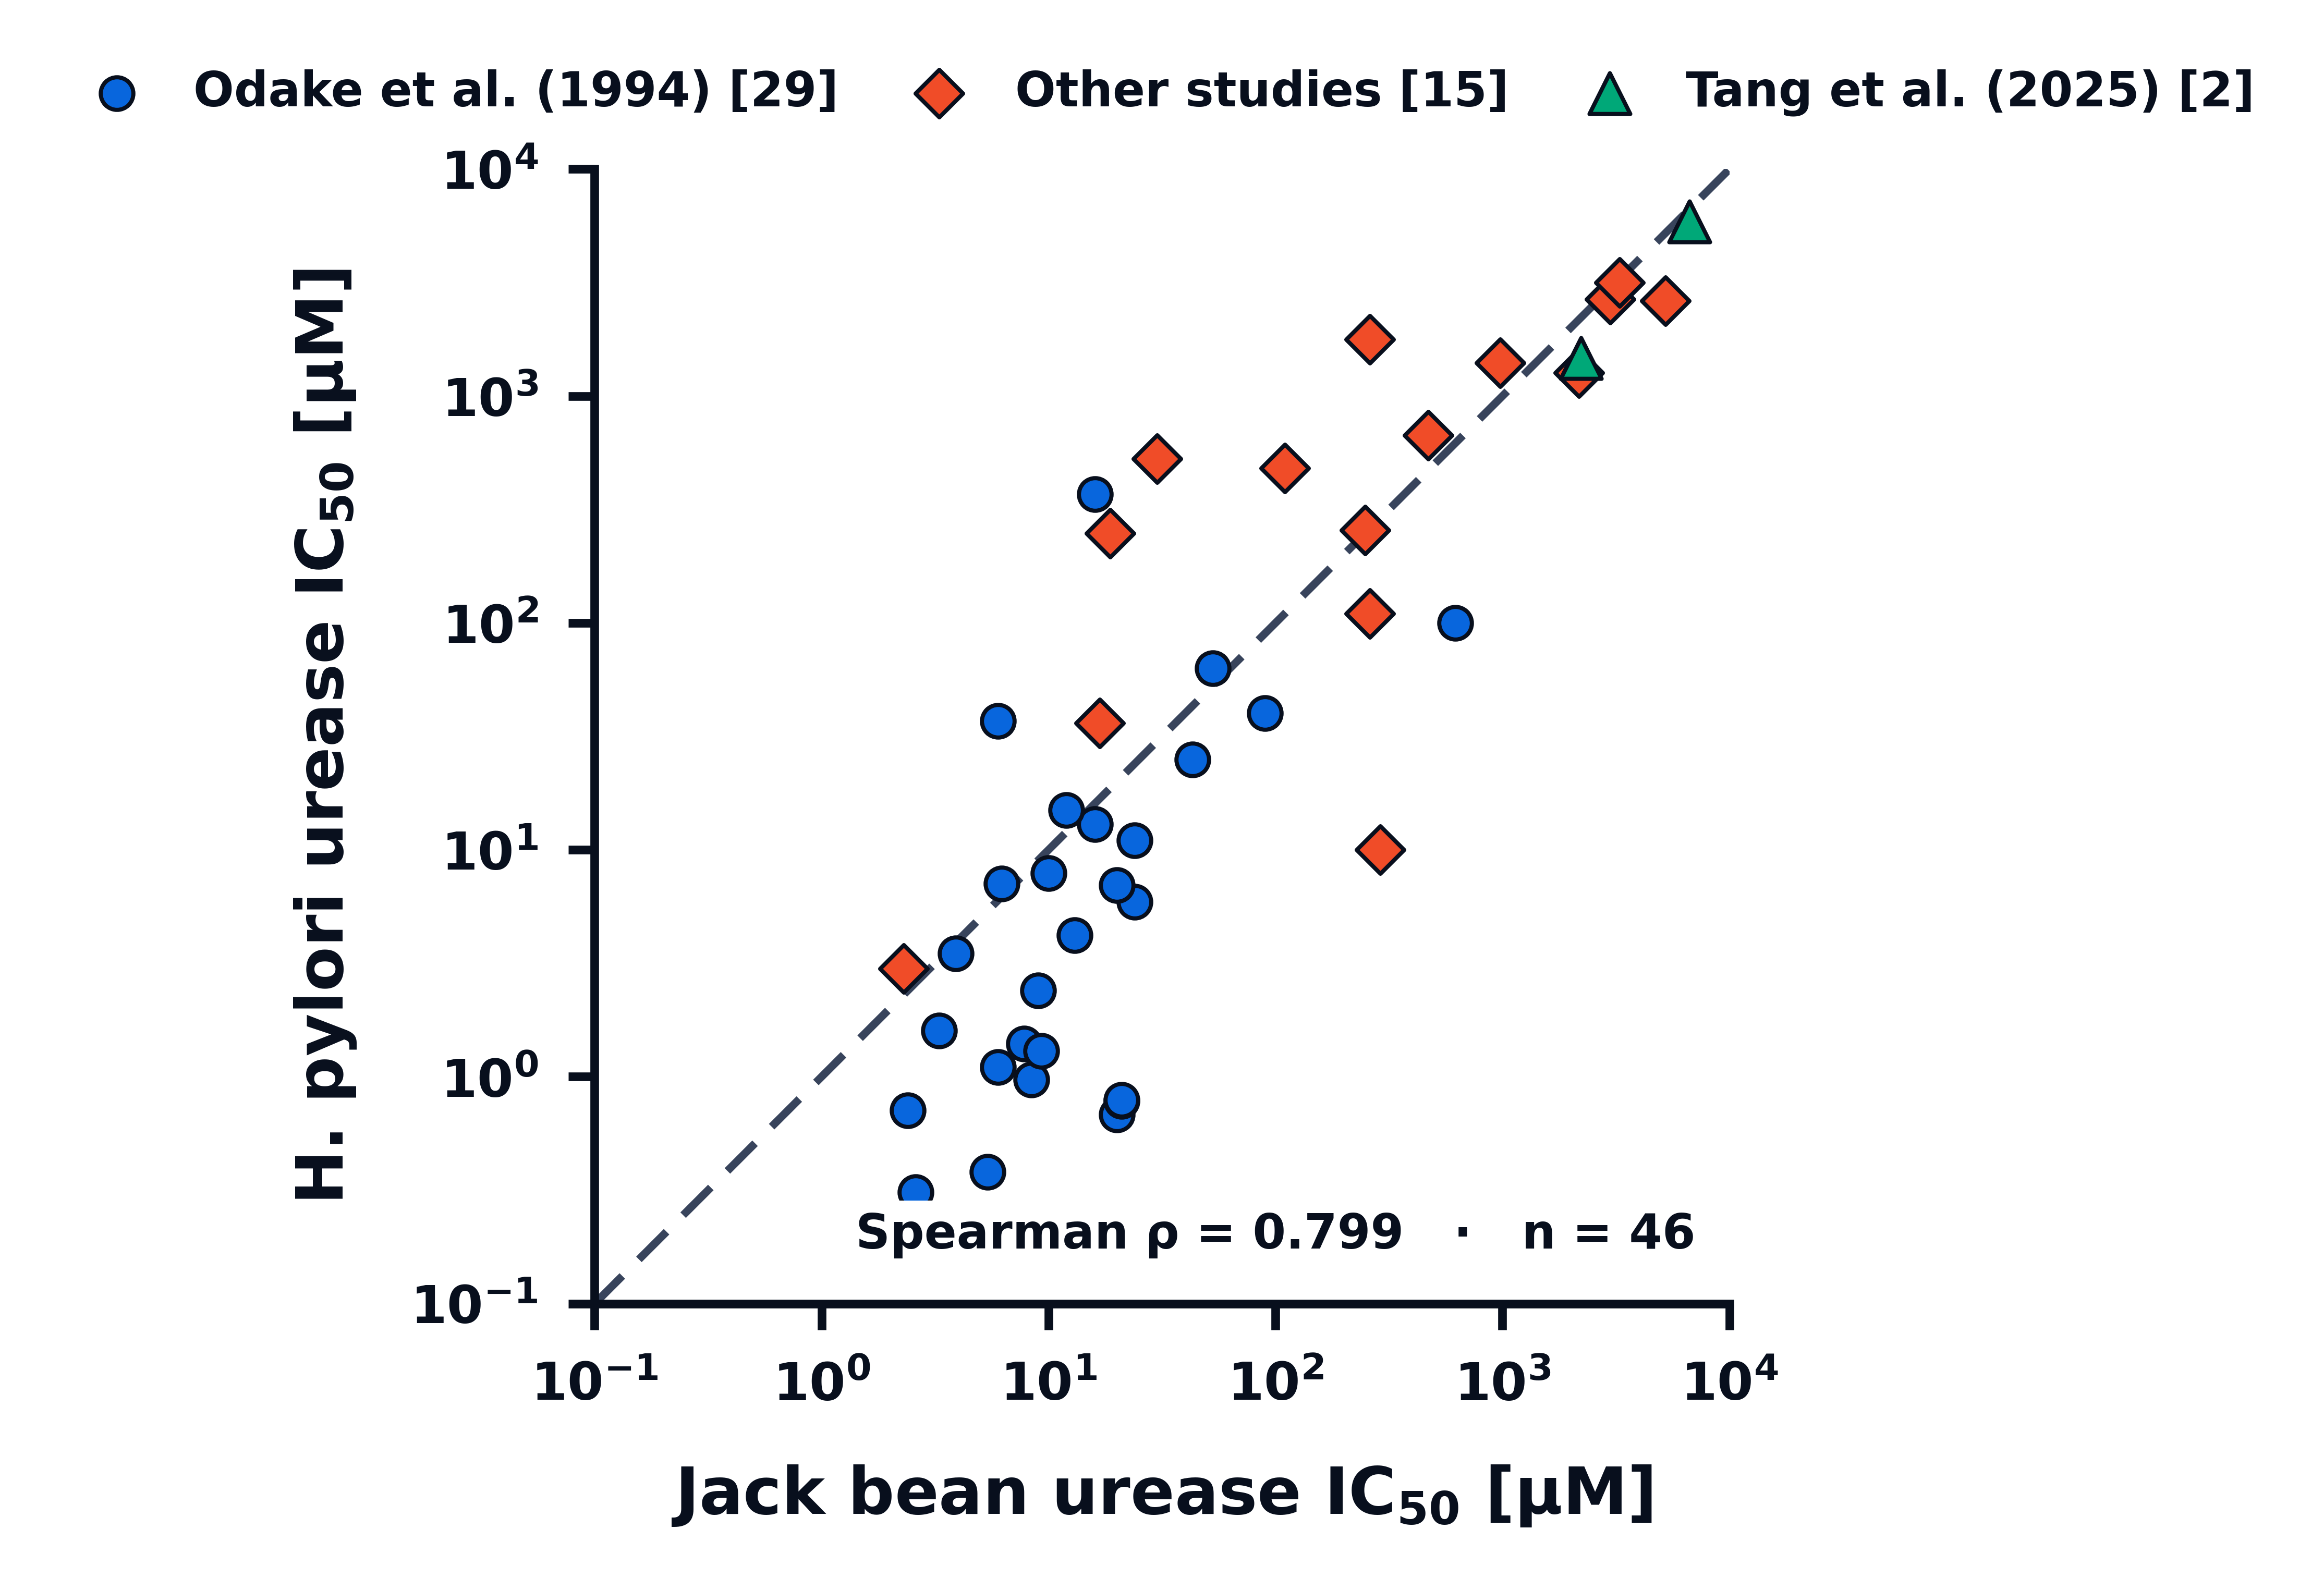

Saved: Fig1_Paired_Potency_46_Prism


In [8]:
# FIGURE 1 — two-species potency, identical log scales, major ticks only.
fig,ax=plt.subplots(figsize=(7.8,5.85))
fig.subplots_adjust(left=.16,right=.98,bottom=.17,top=.79)
od=PAIRS.study_id.eq('Odake_1994'); tg=PAIRS.study_id.eq('Tang_2025'); others=~(od|tg)
settings=[(od,C['navy'],'o','Odake et al. (1994) [29]',marker_area(1.15)),
          (others,C['coral'],'D','Other studies [15]',marker_area(1.22)),
          (tg,C['teal'],'^','Tang et al. (2025) [2]',marker_area(1.8))]
for mask,color,marker,label,sz in settings:
    ax.scatter(PAIRS.loc[mask,'JBU_uM'],PAIRS.loc[mask,'HPU_uM'],
               s=sz, facecolors=color, edgecolors=C['ink'],linewidths=.95,
               alpha=1.0,marker=marker,label=label,zorder=3)
lim=(.1,1e4)
ax.set(xscale='log',yscale='log',xlim=lim,ylim=lim)
# 1:1 equality reference line, deliberately omitted from legend.
if S['equalityLine']:
    ax.plot(lim,lim,color=C['muted'],linewidth=1.8,linestyle=(0,(5,3)),zorder=1,
            label='1:1 equality' if S['equalityLineLegend'] else '_nolegend_')
ax.set_aspect('equal',adjustable='box')
ax.xaxis.set_major_locator(LogLocator(base=10,subs=(1.0,),numticks=8))
ax.yaxis.set_major_locator(LogLocator(base=10,subs=(1.0,),numticks=8))
ax.xaxis.set_major_formatter(LogFormatterMathtext(base=10))
ax.yaxis.set_major_formatter(LogFormatterMathtext(base=10))
ax.xaxis.set_minor_locator(NullLocator())
ax.yaxis.set_minor_locator(NullLocator())
ax.set_xlabel('Jack bean urease IC$_{50}$ [µM]',labelpad=12,fontweight=FW,color=C['ink'])
ax.set_ylabel('H. pylori urease IC$_{50}$ [µM]',labelpad=12,fontweight=FW,color=C['ink'])
leg=ax.legend(loc='lower center',bbox_to_anchor=(.5,1.03),
          ncol=3 if not S['equalityLineLegend'] else 2,frameon=False,fontsize=S['legendPt'],handletextpad=.6,
          columnspacing=1.1,borderaxespad=0)
style_legend(leg)
ax.text(.97,.04,'Spearman ρ = '+format(all_pairs['spearman_rho'],'.3f')+'   ·   n = 46',
        transform=ax.transAxes,ha='right',va='bottom',fontsize=S['legendPt'],fontweight=FW,color=C['ink'],
        bbox=dict(facecolor='white',edgecolor='none',alpha=1.0,pad=2.4))
format_prism_axis(ax)
savefig(fig,'Fig1_Paired_Potency_46_Prism')

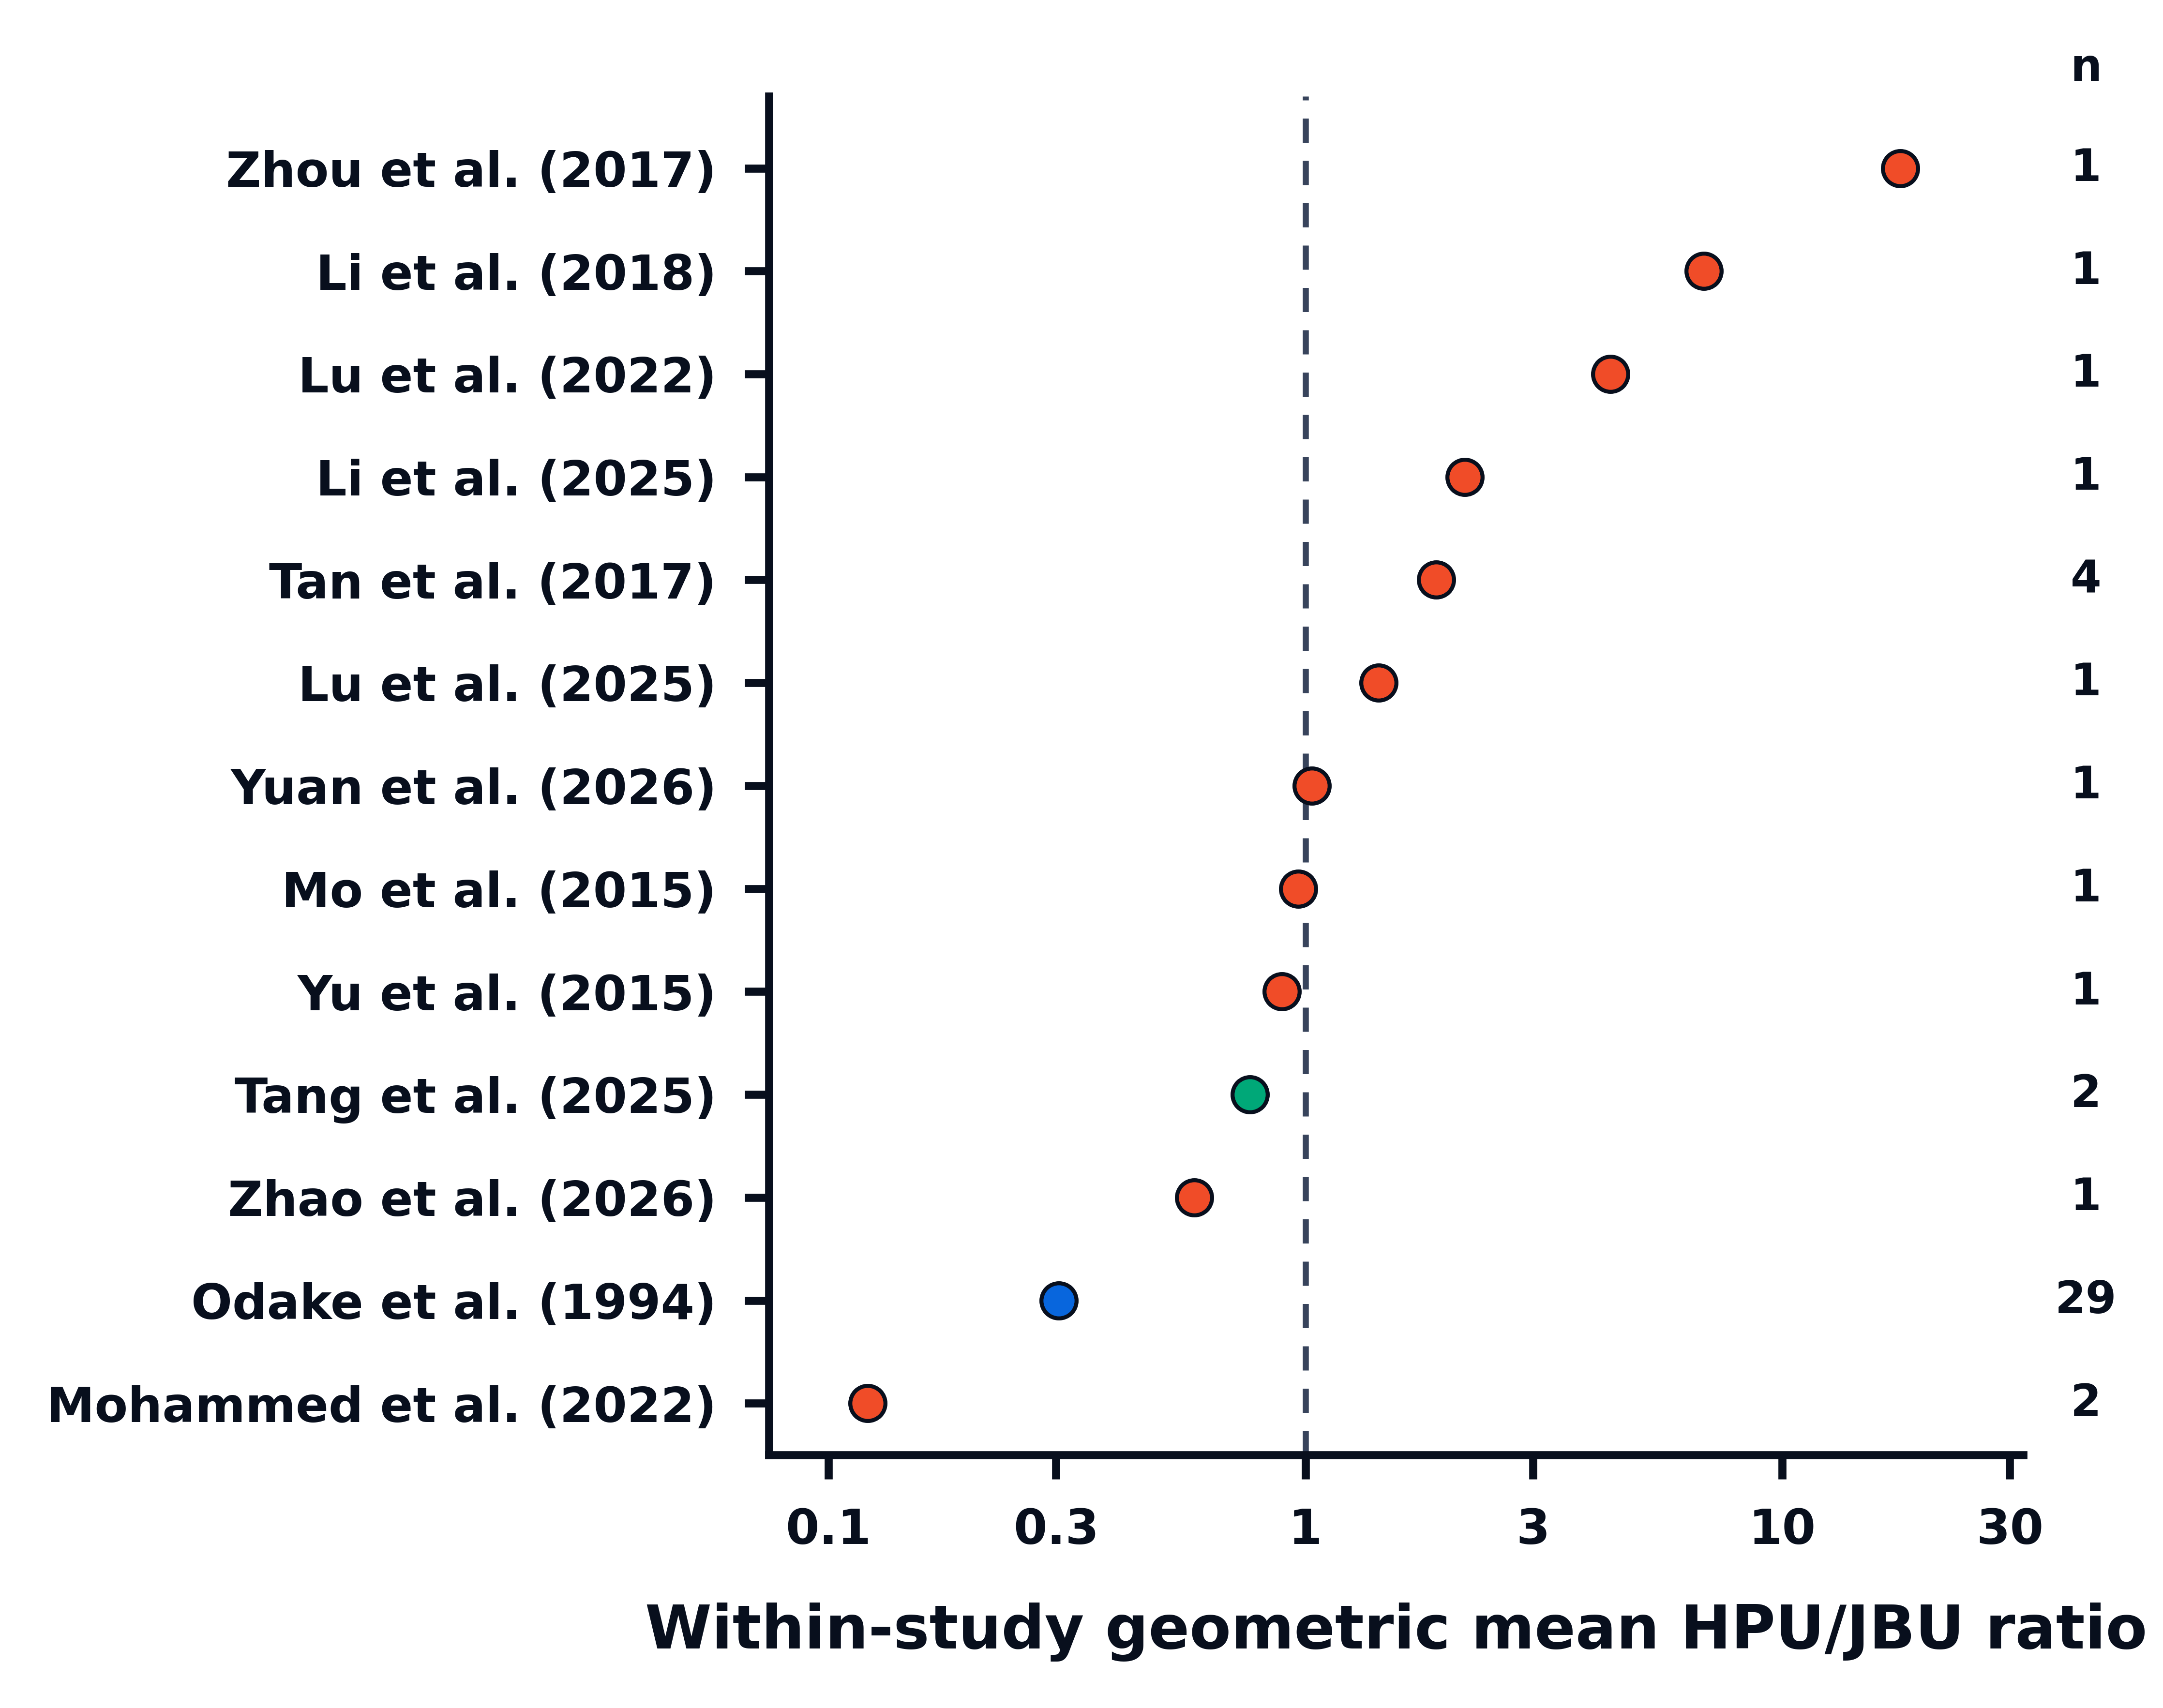

Saved: Fig2_Study_Level_Ratios_13_Prism


In [9]:
# FIGURE 2 — Prism-like grouped study dot plot; no invented standard errors / CIs.
ss=study.sort_values('geo_ratio',ascending=False).reset_index(drop=True)
y=np.arange(len(ss))
fig,ax=plt.subplots(figsize=(8.0,6.0))
fig.subplots_adjust(left=.31,right=.85,bottom=.17,top=.95)
ax.axvline(1,color=C['muted'],linewidth=1.5,linestyle=(0,(4,3)),zorder=1)
for j,row in ss.iterrows():
    col=C['teal'] if row.study_id=='Tang_2025' else (C['navy'] if row.study_id=='Odake_1994' else C['coral'])
    ax.scatter(row.geo_ratio,j,marker='o',s=marker_area(1.55),facecolor=col,edgecolor=C['ink'],lw=1.0,zorder=4)
    ax.text(1.05,j,str(int(row.n_pairs)),transform=ax.get_yaxis_transform(),
            ha='center',va='center',fontsize=S['legendPt'],fontweight=FW,color=C['ink'],clip_on=False)
ax.text(1.05,-.85,'n',transform=ax.get_yaxis_transform(),ha='center',
        fontsize=S['legendPt'],fontweight=FW,color=C['ink'],clip_on=False)
ax.set_yticks(y,[fmt_study(v) for v in ss.study_id]);ax.invert_yaxis()
ax.set_xscale('log');ax.set_xlim(.075,32)
ax.set_xticks([.1,.3,1,3,10,30],labels=['0.1','0.3','1','3','10','30'])
ax.xaxis.set_minor_locator(NullLocator())
ax.set_ylim(len(ss)-.5,-.70)
ax.set_xlabel('Within-study geometric mean HPU/JBU ratio',labelpad=12,fontweight=FW,color=C['ink'])
format_prism_axis(ax)
savefig(fig,'Fig2_Study_Level_Ratios_13_Prism')

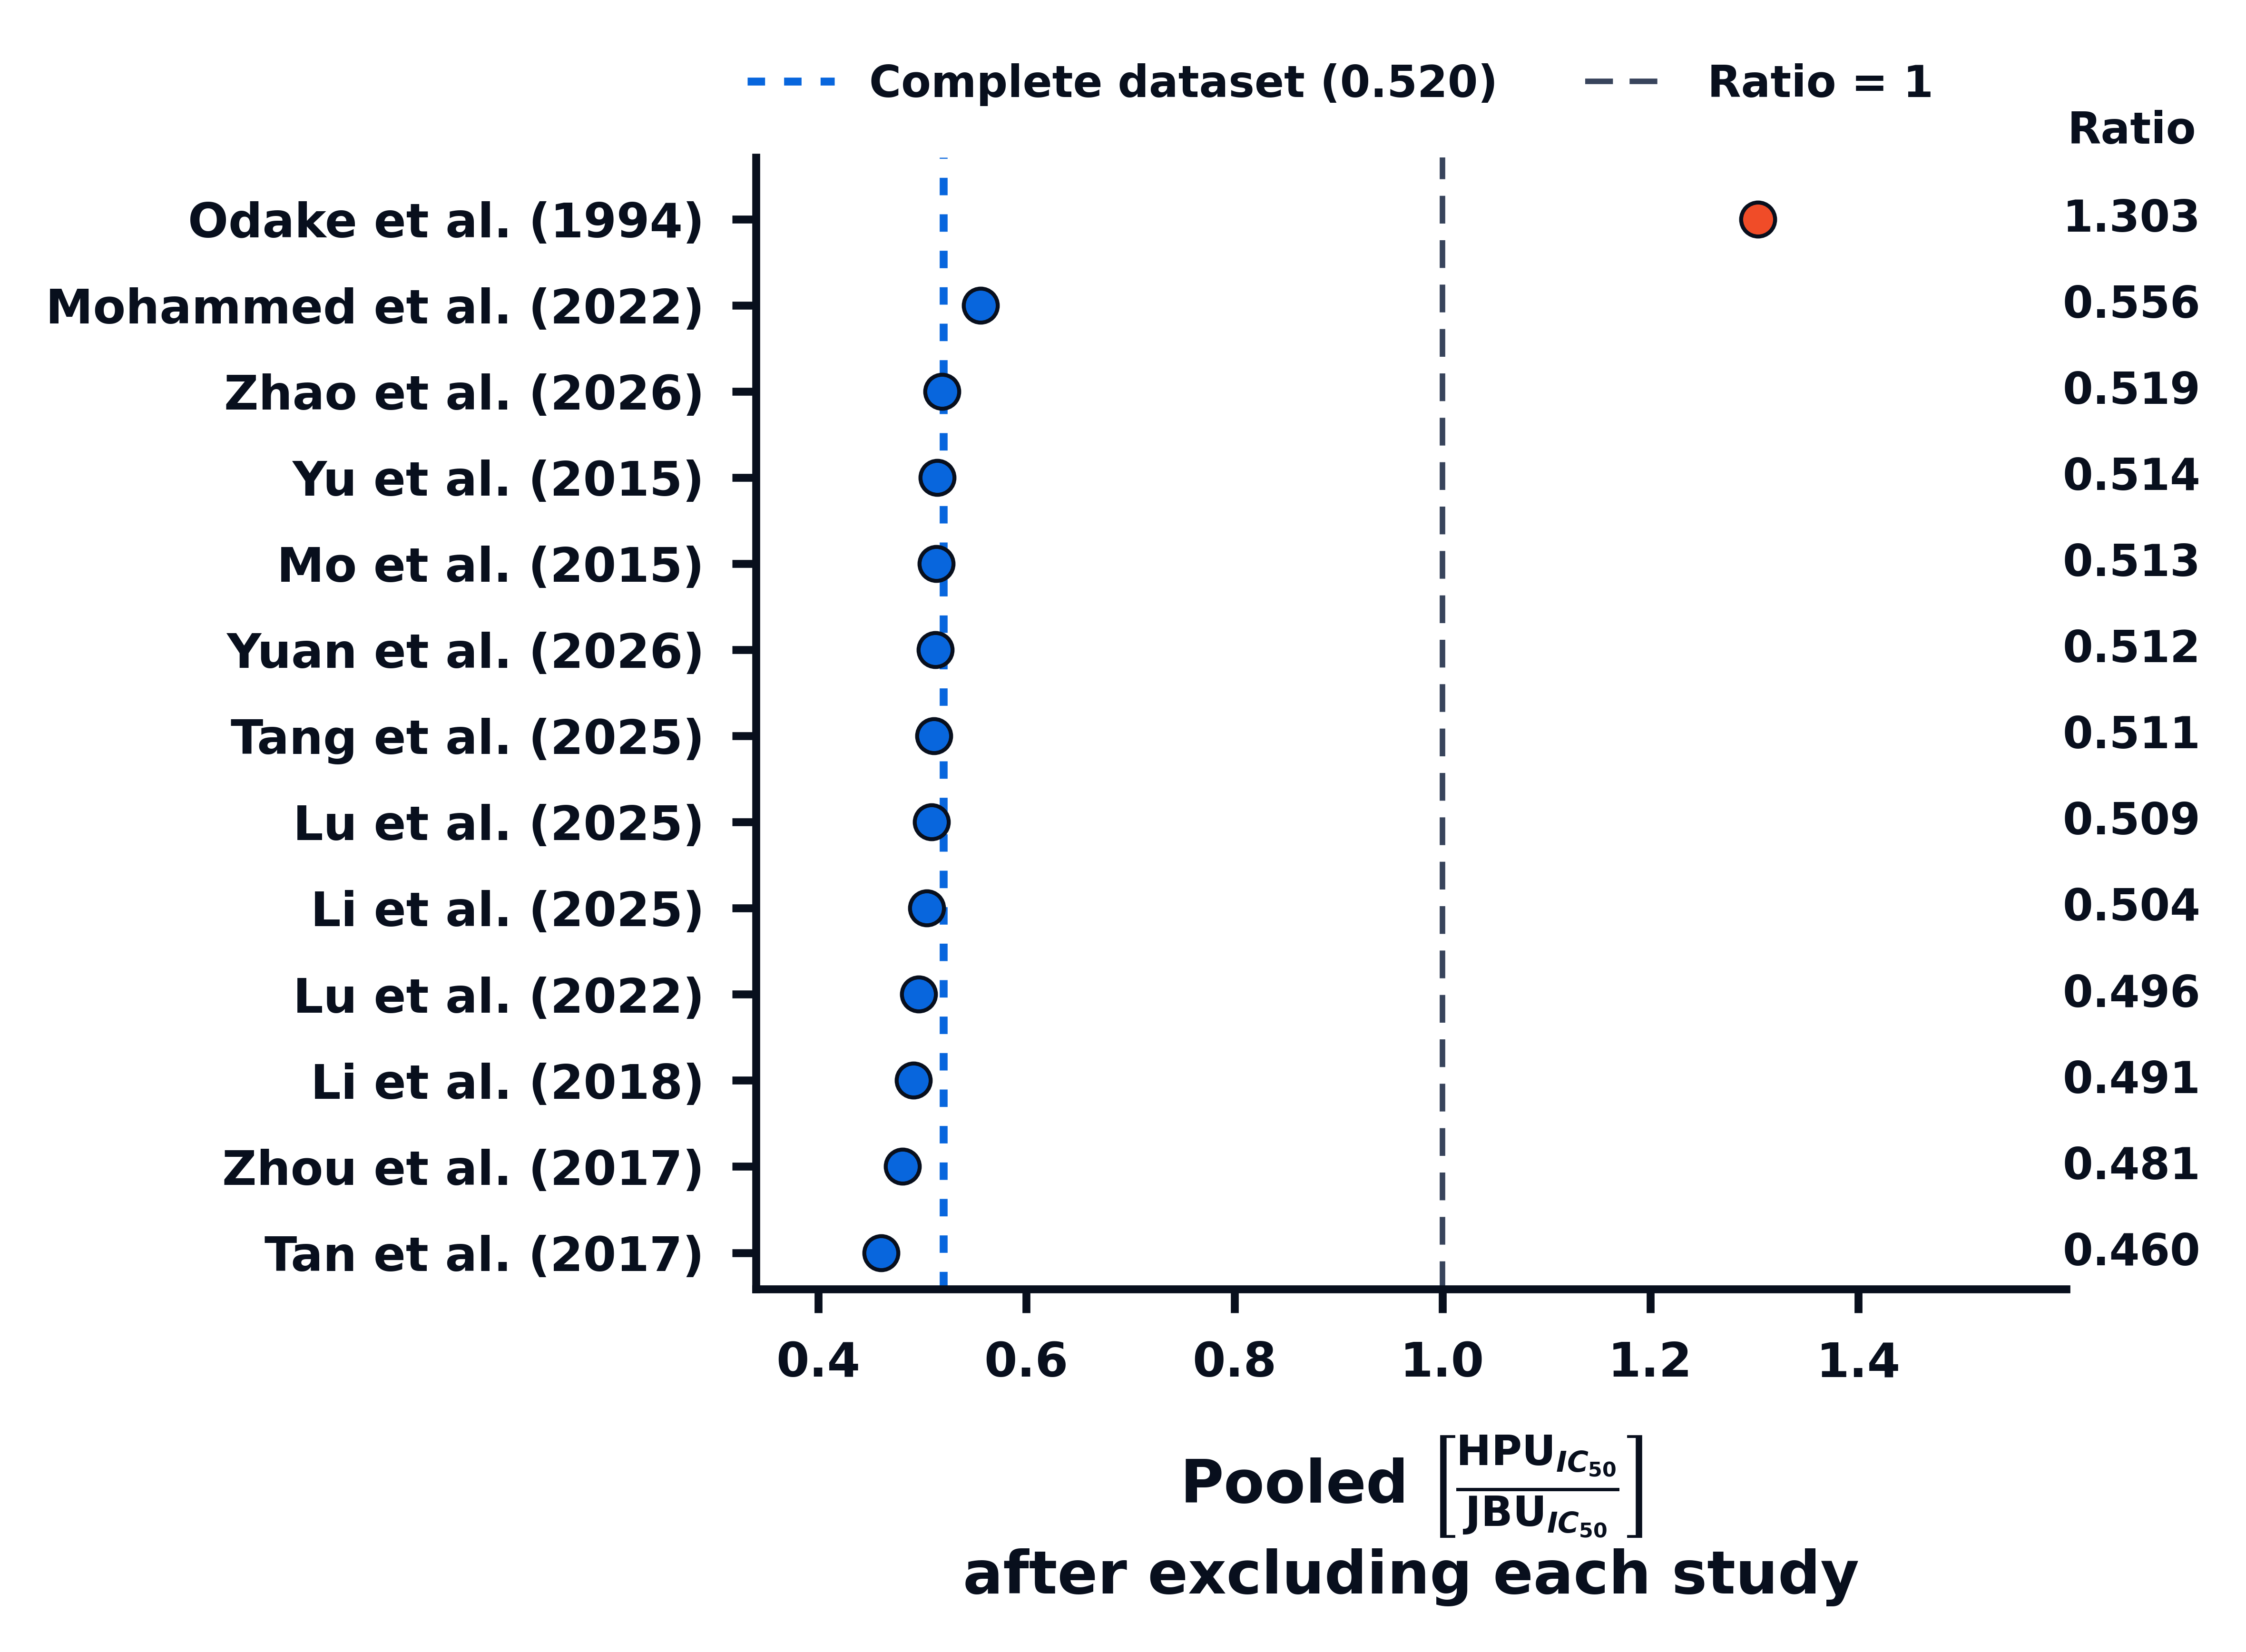

Saved: Fig3_Leave_One_Study_Out_13_Prism


In [10]:
# FIGURE 3 — leave-one-study-out influence as a clean Prism-style dot plot.
ll=LOO.sort_values('pooled_geo_ratio',ascending=False).reset_index(drop=True)
y=np.arange(len(ll));overall=all_pairs['geometric_HPU_over_JBU']
fig,ax=plt.subplots(figsize=(8.5,6.5))
fig.subplots_adjust(left=.30,right=.84,bottom=.27,top=.88)
ax.axvline(overall,color=C['navy'],linestyle=(0,(2.2,2.4)),lw=2.0,
           label=f'Complete dataset ({overall:.3f})',zorder=1)
ax.axvline(1,color=C['muted'],linestyle=(0,(5,3)),lw=1.4,
           label='Ratio = 1',zorder=1)
for j,row in ll.iterrows():
    col=C['coral'] if row.left_out=='Odake_1994' else C['navy']
    ax.scatter(row.pooled_geo_ratio,j,marker='o',s=marker_area(1.5),color=col,
               edgecolor=C['ink'],lw=1.0,zorder=4)
    ax.text(1.05,j,f'{row.pooled_geo_ratio:.3f}',transform=ax.get_yaxis_transform(),
            ha='center',va='center',fontsize=S['legendPt'],fontweight=FW,color=C['ink'],clip_on=False)
ax.text(1.05,-.88,'Ratio',transform=ax.get_yaxis_transform(),
        ha='center',fontweight=FW,fontsize=S['legendPt'],color=C['ink'],clip_on=False)
ax.set_yticks(y,[fmt_study(v) for v in ll.left_out]);ax.invert_yaxis()
ax.set_xlim(.34,1.60);ax.set_xticks([.4,.6,.8,1.,1.2,1.4])
ax.xaxis.set_minor_locator(NullLocator())
ax.set_ylim(len(ll)-.58,-.72)
ax.set_xlabel('Pooled $\\left[\\frac{\\mathrm{HPU}_{IC_{50}}}{\\mathrm{JBU}_{IC_{50}}}\\right]$\nafter excluding each study',labelpad=12,fontweight=FW,color=C['ink'])
leg=ax.legend(loc='lower left',bbox_to_anchor=(-.02,1.03),ncol=2,frameon=False,
          fontsize=S['legendPt'],borderaxespad=0)
style_legend(leg)
format_prism_axis(ax)
savefig(fig,'Fig3_Leave_One_Study_Out_13_Prism')

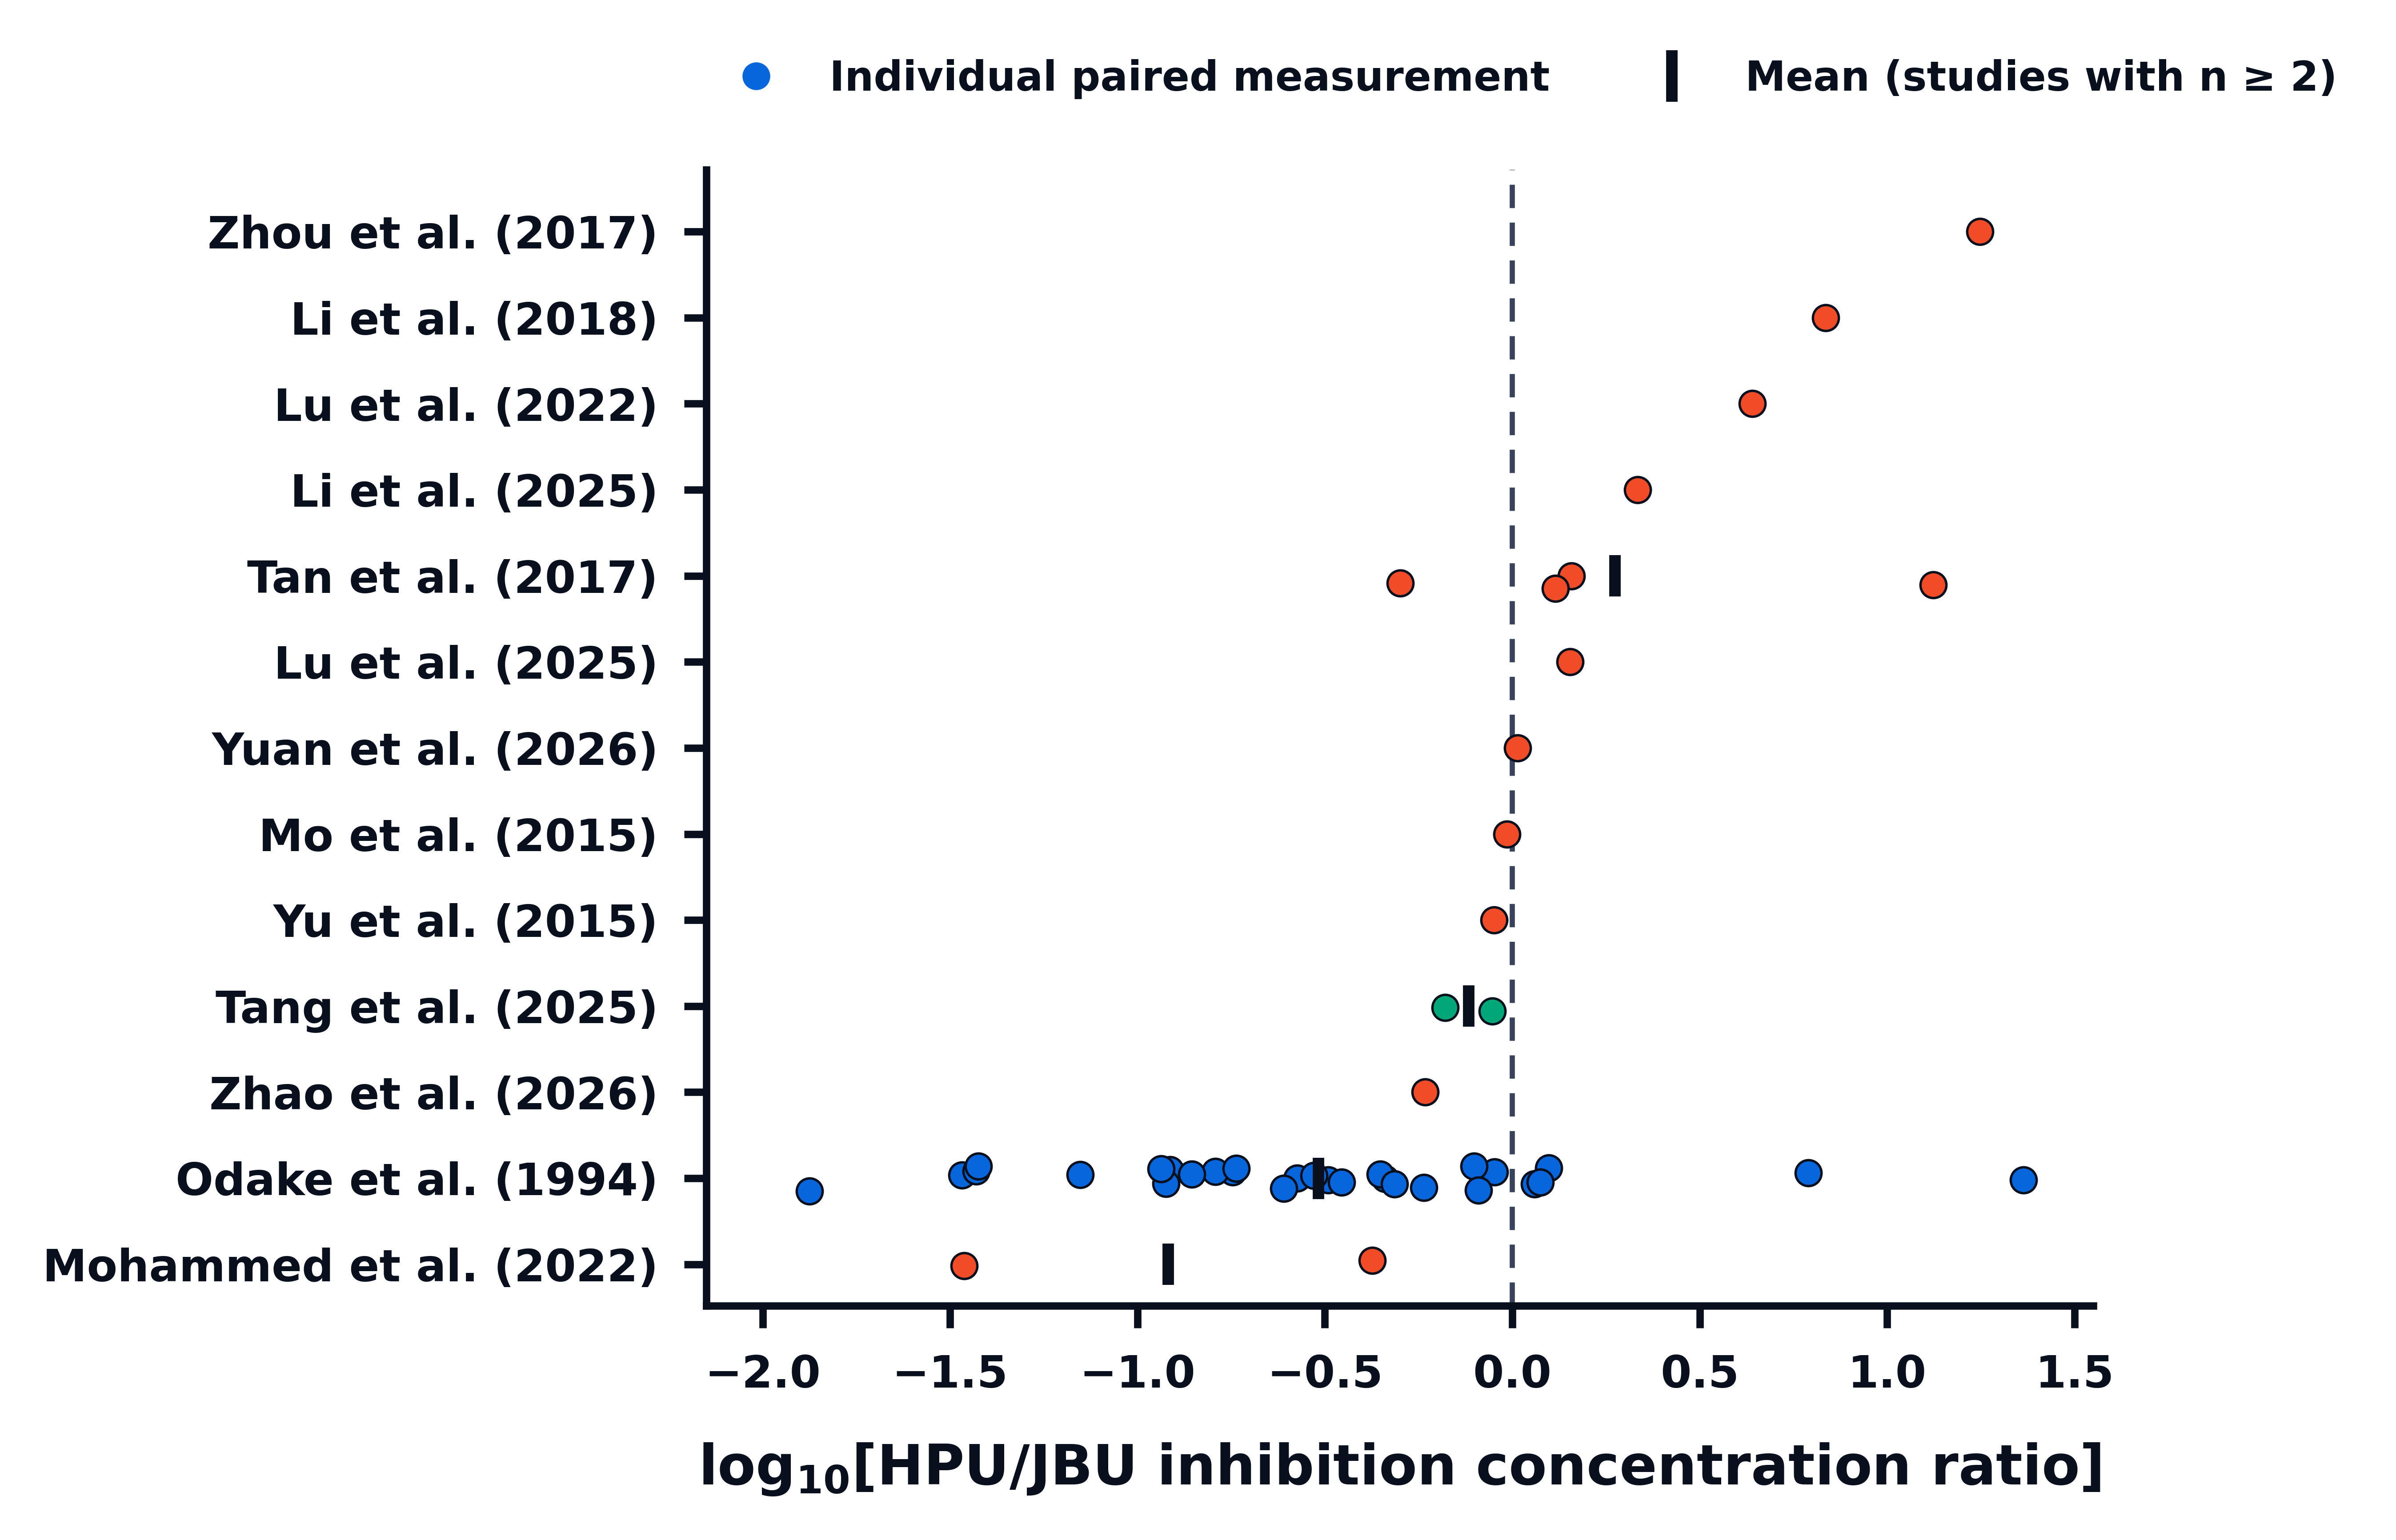

Saved: Fig4_LogRatio_By_Study_13_Prism


In [11]:
# FIGURE 4 — unaggregated ratios within studies (jittered raw observations).
ss=study.sort_values('geo_ratio',ascending=False).reset_index(drop=True)
fig,ax=plt.subplots(figsize=(8.0,6.0))
fig.subplots_adjust(left=.31,right=.96,bottom=.19,top=.90)
ax.axvline(0,color=C['muted'],lw=1.4,linestyle=(0,(4.5,2.8)),zorder=1)
rng=np.random.default_rng(20261017)
for j,row in ss.iterrows():
    k=row.study_id
    v=PAIRS.loc[PAIRS.study_id==k,'log10_ratio'].to_numpy()
    jitter=rng.uniform(-.16,.16,len(v)) if len(v)>1 else np.zeros(len(v))
    col=C['navy'] if k=='Odake_1994' else (C['teal'] if k=='Tang_2025' else C['coral'])
    ax.scatter(v,j+jitter,s=marker_area(1.0),color=col,edgecolors=C['ink'],linewidths=.65,
               alpha=1.0,zorder=3)
    if len(v)>1:
        ax.vlines(v.mean(),j-.24,j+.24,color=C['ink'],lw=3.1,zorder=5)
ax.set_yticks(range(len(ss)),[fmt_study(v) for v in ss.study_id]);ax.invert_yaxis()
ax.set_xlim(-2.15,1.55)
ax.set_xticks([-2,-1.5,-1,-.5,0,.5,1,1.5])
ax.xaxis.set_minor_locator(NullLocator())
ax.set_ylim(len(ss)-.52,-.72)
ax.set_xlabel('log$_{10}$[HPU/JBU inhibition concentration ratio]',labelpad=12,fontweight=FW,color=C['ink'])
leg=ax.legend(handles=[
    Line2D([0],[0],marker='o',color='none',markerfacecolor=C['navy'],
           markeredgecolor='white',markersize=8.5,label='Individual paired measurement'),
    Line2D([0],[0],marker='|',color='none',markeredgecolor=C['ink'],
           markerfacecolor=C['ink'],markeredgewidth=3.1,markersize=14,
           label='Mean (studies with n ≥ 2)')],
    loc='lower left',bbox_to_anchor=(-.02,1.03),ncol=2,frameon=False,fontsize=S['legendPt'])
style_legend(leg)
format_prism_axis(ax)
savefig(fig,'Fig4_LogRatio_By_Study_13_Prism')

In [13]:
PAIRS.assign(study_citation=PAIRS.study_id.map(STUDY_DISPLAY_LABELS)).to_csv(OUTPUT/'46_Paired_Audited_With_Derivations.csv',index=False)
study.assign(study_citation=study.study_id.map(STUDY_DISPLAY_LABELS)).to_csv(OUTPUT/'13_Study_Estimates.csv',index=False)
LOO.assign(omitted_study_citation=LOO.left_out.map(STUDY_DISPLAY_LABELS)).to_csv(OUTPUT/'13_Leave_One_Study_Out.csv',index=False)
SUMMARY.to_csv(OUTPUT/'46_Pairs_Summary.csv',index=False)
(OUTPUT/'Analysis_Results.txt').write_text(f'13 studies, 46 paired observations; Spearman rho={all_pairs["spearman_rho"]:.5f}; compound-weighted geometric HPU/JBU ratio={all_pairs["geometric_HPU_over_JBU"]:.5f}; equal-study ratio={study_ratio:.5f}; study-cluster bootstrap 95% CI {lo:.5f}–{hi:.5f}; excluding Odake: {no_odake["n_pairs"]} pairs in {no_odake["n_studies"]} studies, ratio={no_odake["geometric_HPU_over_JBU"]:.5f}.\nYuan 2026 AHA HPU=0.0192 mg/mL JBU=0.0186 mg/mL; molar mass 75.07 g/mol.\n',encoding='utf8')
print((OUTPUT/'Analysis_Results.txt').read_text())


13 studies, 46 paired observations; Spearman rho=0.79928; compound-weighted geometric HPU/JBU ratio=0.52027; equal-study ratio=1.33940; study-cluster bootstrap 95% CI 0.68107–2.66028; excluding Odake: 17 pairs in 12 studies, ratio=1.30327.
Yuan 2026 AHA HPU=0.0192 mg/mL JBU=0.0186 mg/mL; molar mass 75.07 g/mol.



In [14]:
archive=OUTPUT.parent/'JBU_HPU_46_13_Studies_Figures_Analysis.zip'
with zipfile.ZipFile(archive,'w',compression=zipfile.ZIP_DEFLATED) as z:
 for f in sorted(OUTPUT.iterdir()):
  if f.is_file():z.write(f,arcname=f.name)
print('ZIP saved',archive)


ZIP saved /mnt/data/JBU_HPU_46_13_Studies_Figures_Analysis.zip


In [15]:
# Upload disabled; outputs are saved locally and are not uploaded to Google Drive.
